# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 5. Поиск типичных подпоследовательностей временного ряда.**

In [1]:
%load_ext autoreload
%autoreload 2

Импорт библиотек и модулей

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from modules.snippets import *
from scipy import signal
from stumpy import snippets

C:\Python311\Lib\site-packages\stumpy\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


### **Задача 1. Поиск сниппетов одномерного временного ряда**

В первой задаче необходимо выполнить поиск сниппетов одномерного временного ряда. Расмотрите приведенный ниже пример использования алгоритма SnipperFinder и визуализации полученных результатов для искуственного врменного ряда.

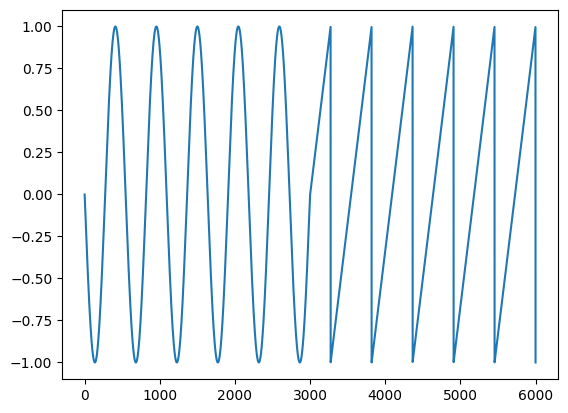

In [3]:
#Создание искусственного временного ряда
t = np.linspace(np.pi, 6 * 2 * np.pi, 3000)
ts = np.concatenate([np.sin(t), signal.sawtooth(t)])
plt.plot(ts)

In [4]:
#Поиск сниппетов
snp = snippets(ts, 600, 2, percentage=0.5)

600


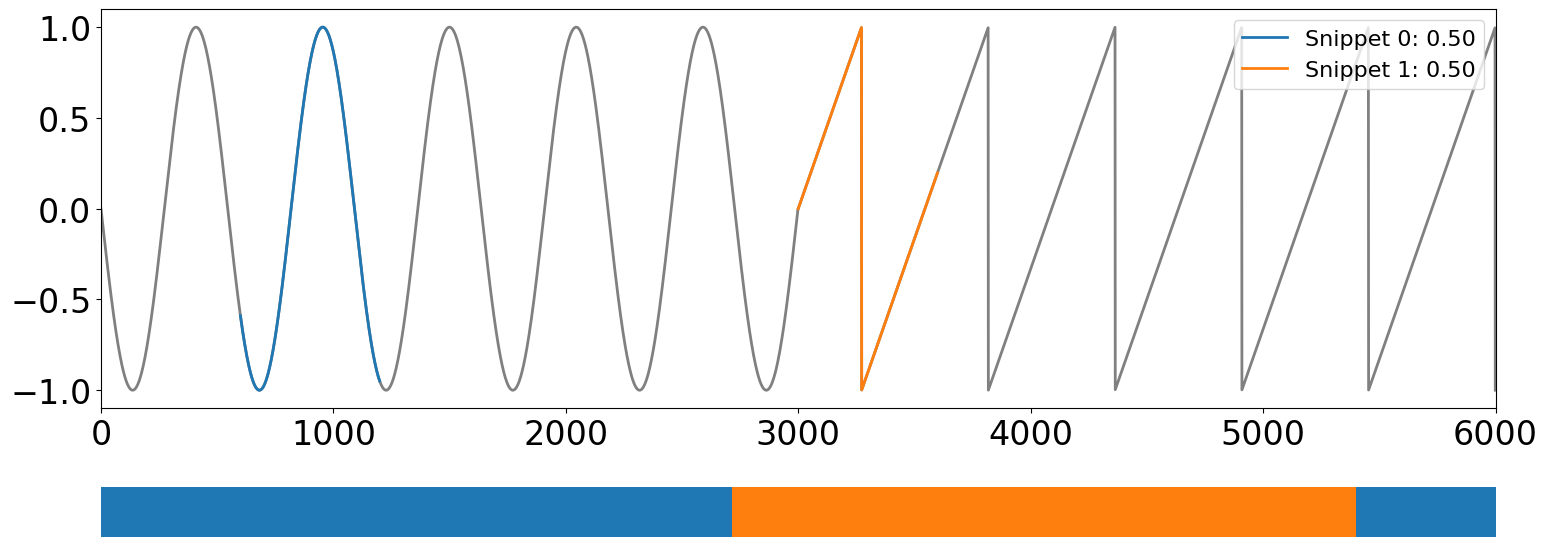

<Axes: >

In [5]:
#Визуализация результатов
plot_snippets(ts, snp)

Далее вам предстоит самостоятельно выполнить поиск top-$k$ типичных подпоследовательностей временного ряда (сниппетов) с помощью алгоритма SnippetFinder на наборе данных PAMAP. Описание набора данных находится в [README-файле](datasets/PAMAP/readme.md).

Выполните считывание временного ряда **показаний гироскопа на оси «Y» (угол тангажа) на временном интервале от 1790 сек. до 1930 сек.** (используя колонку с временными метками) из файла *PAMAP.txt*, который располагается в директории *./datasets/PAMAP*. Затем выполните поиск сниппетов с помощью функции `snippets()` из библиотеки stumpy. Затем визуализируйте полученные результаты, используя функцию `plot_snippets()` из модуля snippets.py.

In [6]:
# Загружаем данные PAMAP
pamap_path = './datasets/PAMAP/PAMAP.txt'
df = pd.read_csv(pamap_path, sep=r'\s+', header=None)
df = df.T

# Берём интервал от 1790 до 1930 секунд
mask = (df[0] >= 1790) & (df[0] <= 1930)
subset = df.loc[mask]

# Показания гироскопа по оси Y (угол тангажа) — колонка 12
ts = subset[11].to_numpy(dtype=np.float64)

# Убираем NaN (пропуски из-за беспроводной передачи данных)
ts = ts[~np.isnan(ts)]

Выполните визулизацию временного ряда и найденных сниппетов с помощью функции `plot_snippets()` из модуля snippets.py.

100
100


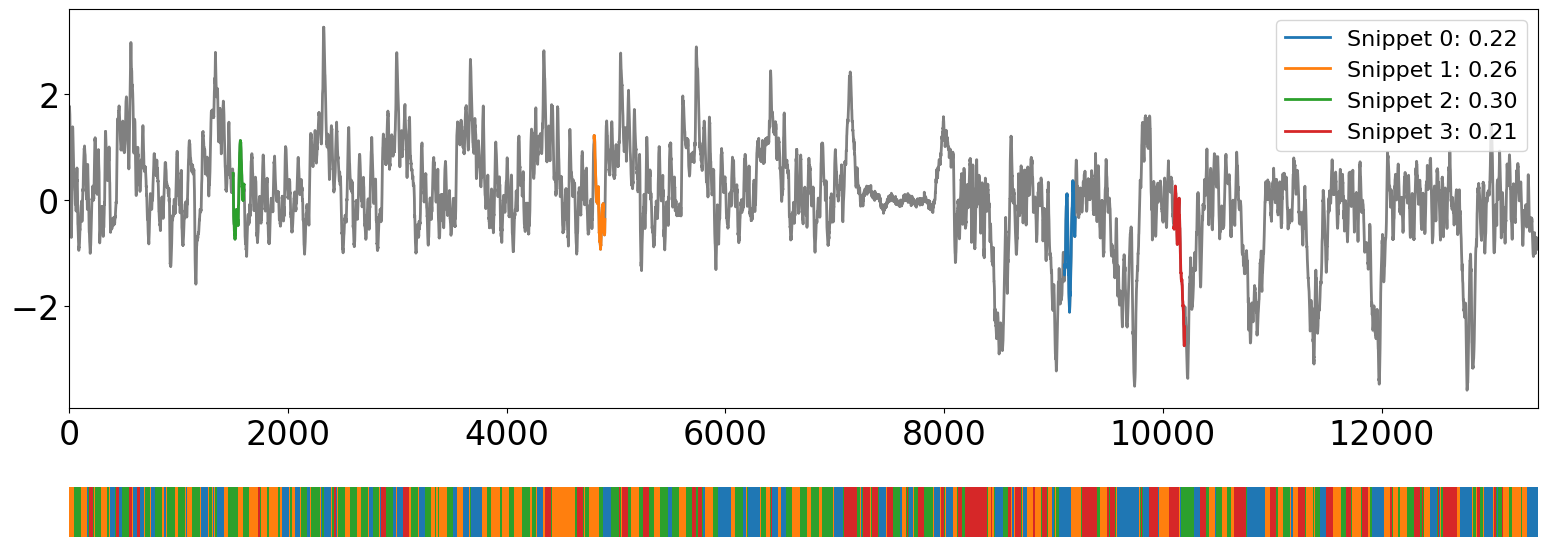

<Axes: >

In [7]:
m = 100   # длина сниппета
k = 4     # количество сниппетов

snp = snippets(ts, m, k, percentage=0.5)
print(m)

plot_snippets(ts, snp)

Оцените точность разметки, полученной при помощи сниппетов, используя исходные данные об активностях в ряде.

In [8]:
from scipy.stats import mode

mask_time = (df[0] >= 1790) & (df[0] <= 1930)
subset = df.loc[mask_time]

gyro_y_all = subset[11].to_numpy(dtype=np.float64)
labels_all = subset[1].to_numpy()

valid = (~np.isnan(gyro_y_all)) & (labels_all != 0)
ts_clean = gyro_y_all[valid]
labels_clean = labels_all[valid].astype(int)

print(f'Длина ts_clean: {len(ts_clean)}')
print(f'Длина labels_clean: {len(labels_clean)}')

m = 100
k = 4
snp = snippets(ts_clean, m, k, percentage=0.5)

snp_profile = np.argmin(snp[2], axis=0)

print(f'Длина snp_profile: {len(snp_profile)}')
print(f'Уникальные сниппеты в профиле: {np.unique(snp_profile)}')

n_profile = len(snp_profile)
labels_for_profile = labels_clean[:n_profile]

assert len(snp_profile) == len(labels_for_profile)

mapping = {}
for snippet_id in np.unique(snp_profile):
    mask_snip = snp_profile == snippet_id
    if mask_snip.sum() > 0:
        mapping[snippet_id] = int(mode(labels_for_profile[mask_snip],
                                       keepdims=False).mode)

predicted = np.array([mapping[s] for s in snp_profile], dtype=int)

accuracy = np.mean(predicted == labels_for_profile)
print(f'\nAccuracy (1D, ось Y): {accuracy:.4f}')
print(f'Маппинг сниппет->активность: {mapping}')

Длина ts_clean: 13430
Длина labels_clean: 13430
Длина snp_profile: 13331
Уникальные сниппеты в профиле: [0 1 2 3]

Accuracy (1D, ось Y): 0.6228
Маппинг сниппет->активность: {0: 12, 1: 12, 2: 12, 3: 13}


❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Точность не совсем высокая, некоторые найденные сниппеты показывают одинаковые активности, возможно это связано с недостатком данных (анализируем только движенние по одной оси) и могут быть помехи.

### Задача 2. Разметка многомерного временного ряда

Выполните разметку многомерного временно ряда, используя **показания гироскопа по всем трем осям** из набора данных PAMAP. Используйте тот же временной интервал, что и в задаче 1. Итоговую разметку получите в результате голосования большинством.

In [9]:
from scipy.stats import mode

mask_time = (df[0] >= 1790) & (df[0] <= 1930)
subset_md = df.loc[mask_time]

gyro_all = subset_md[[10, 11, 12]].to_numpy(dtype=np.float64)
labels_all = subset_md[1].to_numpy()

valid = (~np.isnan(gyro_all).any(axis=1)) & (labels_all != 0)
ts_md = gyro_all[valid]
labels_md = labels_all[valid].astype(int)

print(f'ts_md shape: {ts_md.shape}')          # (N, 3)
print(f'labels_md shape: {labels_md.shape}')  # (N,)
print(f'Уникальные активности: {np.unique(labels_md)}')

m = 100
k = 4
n_axes = ts_md.shape[1]

profiles = []
for axis in range(n_axes):
    ts_axis = ts_md[:, axis]
    snp_axis = snippets(ts_axis, m, k, percentage=0.5)

    profile_axis = np.argmin(snp_axis[2], axis=0)

    profiles.append(profile_axis)

n_profile = len(profiles[0])
assert all(len(p) == n_profile for p in profiles), "Профили разной длины!"

labels_for_profile = labels_md[:n_profile]
assert len(labels_for_profile) == n_profile

predictions_per_axis = []

for axis, profile_axis in enumerate(profiles):
    mapping = {}
    for snippet_id in np.unique(profile_axis):
        mask_snip = profile_axis == snippet_id
        if mask_snip.sum() > 0:
            mapping[snippet_id] = int(mode(labels_for_profile[mask_snip],
                                           keepdims=False).mode)
    predicted_axis = np.array([mapping[s] for s in profile_axis], dtype=int)
    predictions_per_axis.append(predicted_axis)

predictions_per_axis = np.array(predictions_per_axis)

def majority_vote(values):
    counts = np.bincount(values)
    return int(np.argmax(counts))

predicted_md = np.array(
    [majority_vote(predictions_per_axis[:, i]) for i in range(n_profile)],
    dtype=int
)

ts_md shape: (13430, 3)
labels_md shape: (13430,)
Уникальные активности: [12 13]


Оцените точность разметки многомерного ряда, используя исходные данные об активностях.

In [10]:
print(f'\nAccuracy по осям:')
accuracy_md = np.mean(predicted_md == labels_for_profile)
for axis in range(predictions_per_axis.shape[0]):
    acc_axis = np.mean(predictions_per_axis[axis] == labels_for_profile)
    print(f'  Ось {axis}: {acc_axis:.4f}')

print(f'\nAccuracy многомерной разметки (голосование большинством): '
      f'{accuracy_md:.4f}')

# Сравнение с лучшей одиночной осью
acc_best_axis = max(
    np.mean(predictions_per_axis[axis] == labels_for_profile)
    for axis in range(predictions_per_axis.shape[0])
)
print(f'Лучшая одиночная ось: {acc_best_axis:.4f}')
print(f'Прирост от многомерности: {accuracy_md - acc_best_axis:+.4f}')


Accuracy по осям:
  Ось 0: 0.5840
  Ось 1: 0.6228
  Ось 2: 0.5973

Accuracy многомерной разметки (голосование большинством): 0.6373
Лучшая одиночная ось: 0.6228
Прирост от многомерности: +0.0145


❓ Проанализируйте и изложите содержательный смысл полученных результатов. Сравните полученные разметки многомерного и одномерного рядов.

Использование большего количества осей привело к приросту точности на 0.0145, что очень мало, можно сделать вывод что записи в трех осях координат независимы друг от друга.

## Задача 3. Подбор оптимального значения _k_


Разработайте программу, которая выполняет выполняет вычисление меры $change$ для различных значений $k$ с помощью алгоритма SnippetFinder. Проведите эксперименты, используя временной ряд из задания 2 (взяв 1 ≤ _k_ ≤ 9).

$Change_k = \frac{ProfileArea_{k-1}}{ProfileArea_k} - 1$

In [11]:
m = 100
k_values = list(range(1, 10))
n_axes = ts_md.shape[1]

profile_areas = []   # средняя площадь по осям для каждого k

for k in k_values:
    area_per_axis = []
    for axis in range(n_axes):
        ts_axis = ts_md[:, axis]
        snp_k = snippets(ts_axis, m, k, percentage=0.5)

        profile_distances = np.min(snp_k[2], axis=0)

        area_per_axis.append(float(np.sum(profile_distances)))

    profile_areas.append(np.mean(area_per_axis))   # усреднение по осям
    print(f'k={k}: ProfileArea = {profile_areas[-1]:.4f}')

changes = [np.nan]
for i in range(1, len(profile_areas)):
    ch = profile_areas[i-1] / profile_areas[i] - 1
    changes.append(ch)

print('\n=== Результаты ===')
print(f'{"k":>3} | {"ProfileArea":>14} | {"change":>10}')
print('-' * 34)
for k, pa, ch in zip(k_values, profile_areas, changes):
    ch_str = '—' if np.isnan(ch) else f'{ch:.4f}'
    print(f'{k:>3} | {pa:>14.4f} | {ch_str:>10}')

k=1: ProfileArea = 42178.6690
k=2: ProfileArea = 36669.1184
k=3: ProfileArea = 34254.7702
k=4: ProfileArea = 32539.0680
k=5: ProfileArea = 31508.8601
k=6: ProfileArea = 30633.7903
k=7: ProfileArea = 29892.0848
k=8: ProfileArea = 29263.6513
k=9: ProfileArea = 28664.1013

=== Результаты ===
  k |    ProfileArea |     change
----------------------------------
  1 |     42178.6690 |          —
  2 |     36669.1184 |     0.1503
  3 |     34254.7702 |     0.0705
  4 |     32539.0680 |     0.0527
  5 |     31508.8601 |     0.0327
  6 |     30633.7903 |     0.0286
  7 |     29892.0848 |     0.0248
  8 |     29263.6513 |     0.0215
  9 |     28664.1013 |     0.0209


Выполните визуализацию результатов экспериментов в следующем виде: отображение столбчатых диаграм со значениями $ProfileArea$ и меры $change$ в зависимости от $k$.

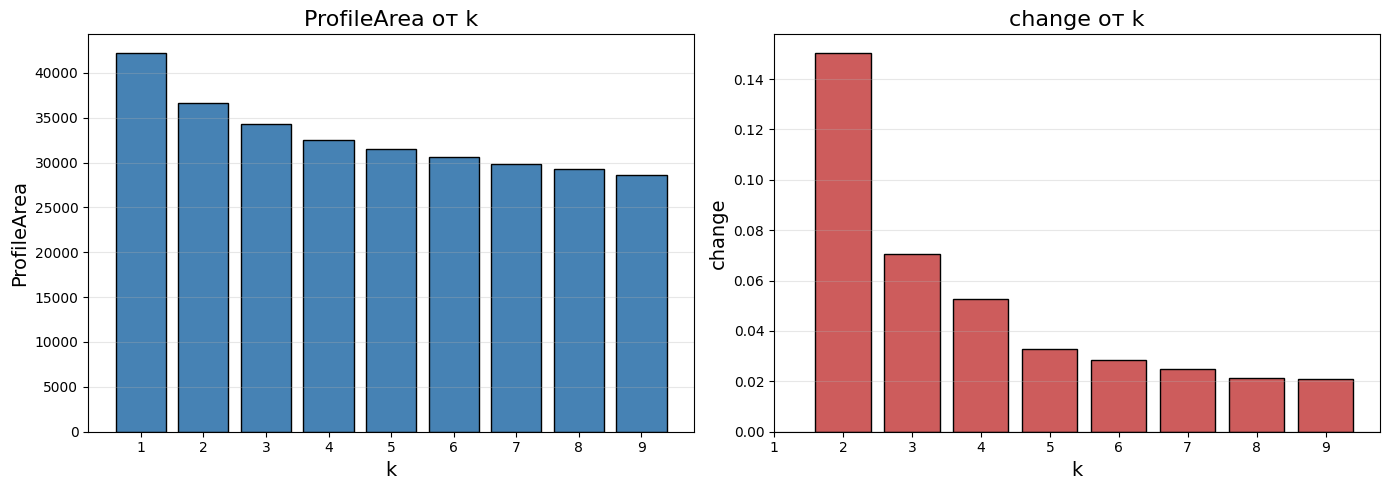

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- ProfileArea(k) ----
axes[0].bar(k_values, profile_areas, color='steelblue', edgecolor='black')
axes[0].set_xlabel('k', fontsize=14)
axes[0].set_ylabel('ProfileArea', fontsize=14)
axes[0].set_title('ProfileArea от k', fontsize=16)
axes[0].set_xticks(k_values)
axes[0].grid(axis='y', alpha=0.3)

# ---- change(k) ----
changes_plot = [np.nan if np.isnan(c) else c for c in changes]
axes[1].bar(k_values, changes_plot, color='indianred', edgecolor='black')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('k', fontsize=14)
axes[1].set_ylabel('change', fontsize=14)
axes[1].set_title('change от k', fontsize=16)
axes[1].set_xticks(k_values)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов. Какое значение $k$ является наилучшим для используемого временного ряда?

ProfileArea монотонно убывает, так как больше сниппетов = лучше покрытие.
Мера change показывает "эффективность" добавления нового сниппета.
Оптимальное количество сниппетов по графику - 2, так как после него, убывание выходит на "плато" и увеличение числа сниппетов приведет только к переобучению.
Это означает, что основная структура ряда описывается всего двумя типичными паттернами (12 и 13).